# Hierarchical clustering applied to the states of Mexico

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy.cluster.hierarchy as shc

Indicators of the multidimensional measurement of poverty in Mexico (CONEVAL), for the 32 states. Each variable is the proportion of the population of the state with a deprivation:

| Variable | Proportion of the population with |
|---|---|
| `ic_rezedu` | educational lag |
| `ic_asalud` | no access to health services |
| `ic_segsoc` | no access to social security |
| `ic_cv` | deprivation in quality and space of the dwelling |
| `ic_sbv` | no access to basic services in the dwelling |
| `ic_ali` | no access to food |
| `plb_m` | income below the minimum welfare line (extreme poverty by income) |
| `plb` | income below the welfare line (poverty by income) |
| `carencias` | at least one social deprivation |
| `carencias3` | at least three social deprivations |

All the variables are proportions, in the same scale, so we do not transform them.

In [2]:
data = pd.read_csv('states.csv')
data.head()

,ent,ic_rezedu,ic_asalud,ic_segsoc,ic_cv,ic_sbv,ic_ali,plb_m,plb,carencias,carencias3
0,Aguascalientes,0.142287,0.114783,0.436842,0.054453,0.033492,0.132084,0.081845,0.348120,0.578463,0.065543
1,Baja California,0.183212,0.165250,0.508806,0.114343,0.214054,0.161483,0.048191,0.262245,0.713572,0.156663
2,Baja California Sur,0.147886,0.107530,0.433600,0.150851,0.126998,0.182310,0.052862,0.237365,0.640536,0.124807
3,Campeche,0.168554,0.116488,0.604795,0.162965,0.377114,0.272834,0.176938,0.500662,0.772908,0.273864
4,Coahuila,0.130634,0.134433,0.314022,0.045933,0.054654,0.189518,0.071404,0.340874,0.523485,0.077275


In [3]:
state_names = data['ent']
state_names = state_names.tolist()

data = data.drop('ent', axis=1)

In [4]:
palette = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#56B4E9', '#D55E00', '#B8A800']

def cut_height(Z, n_clusters):
    # A height between the merge that leaves n_clusters clusters and the next one
    return (Z[-n_clusters, 2] + Z[-n_clusters+1, 2])/2

def plot_dendrogram(ax, Z, n_clusters=None, title='', font_size=9):
    # Horizontal dendrogram with the names of the states, the clusters in colors and the cut if n_clusters is given
    shc.set_link_color_palette(palette)
    threshold = cut_height(Z, n_clusters) if n_clusters else 0
    shc.dendrogram(Z, ax=ax, labels=state_names, orientation='right', leaf_font_size=font_size,
                   color_threshold=threshold, above_threshold_color='#555555')
    if n_clusters:
        ax.axvline(threshold, ls='--', color='#c1121f', lw=1.5)
    ax.set_xlabel('Distance between the merged clusters')
    ax.set_title(title)
    ax.grid(True, axis='x', alpha=0.25)

def ordered_clusters(Z, n_clusters):
    # Cluster of each observation, numbered in the order of the dendrogram (to match its colors)
    labels = shc.fcluster(Z, n_clusters, criterion='maxclust')
    leaves = shc.leaves_list(Z)
    order = pd.unique(labels[leaves])
    return np.array([np.where(order == label)[0][0] for label in labels])

## The four linkages

With every linkage, Chiapas, Guerrero and Oaxaca (with Veracruz) are together and are the last ones to join the rest.

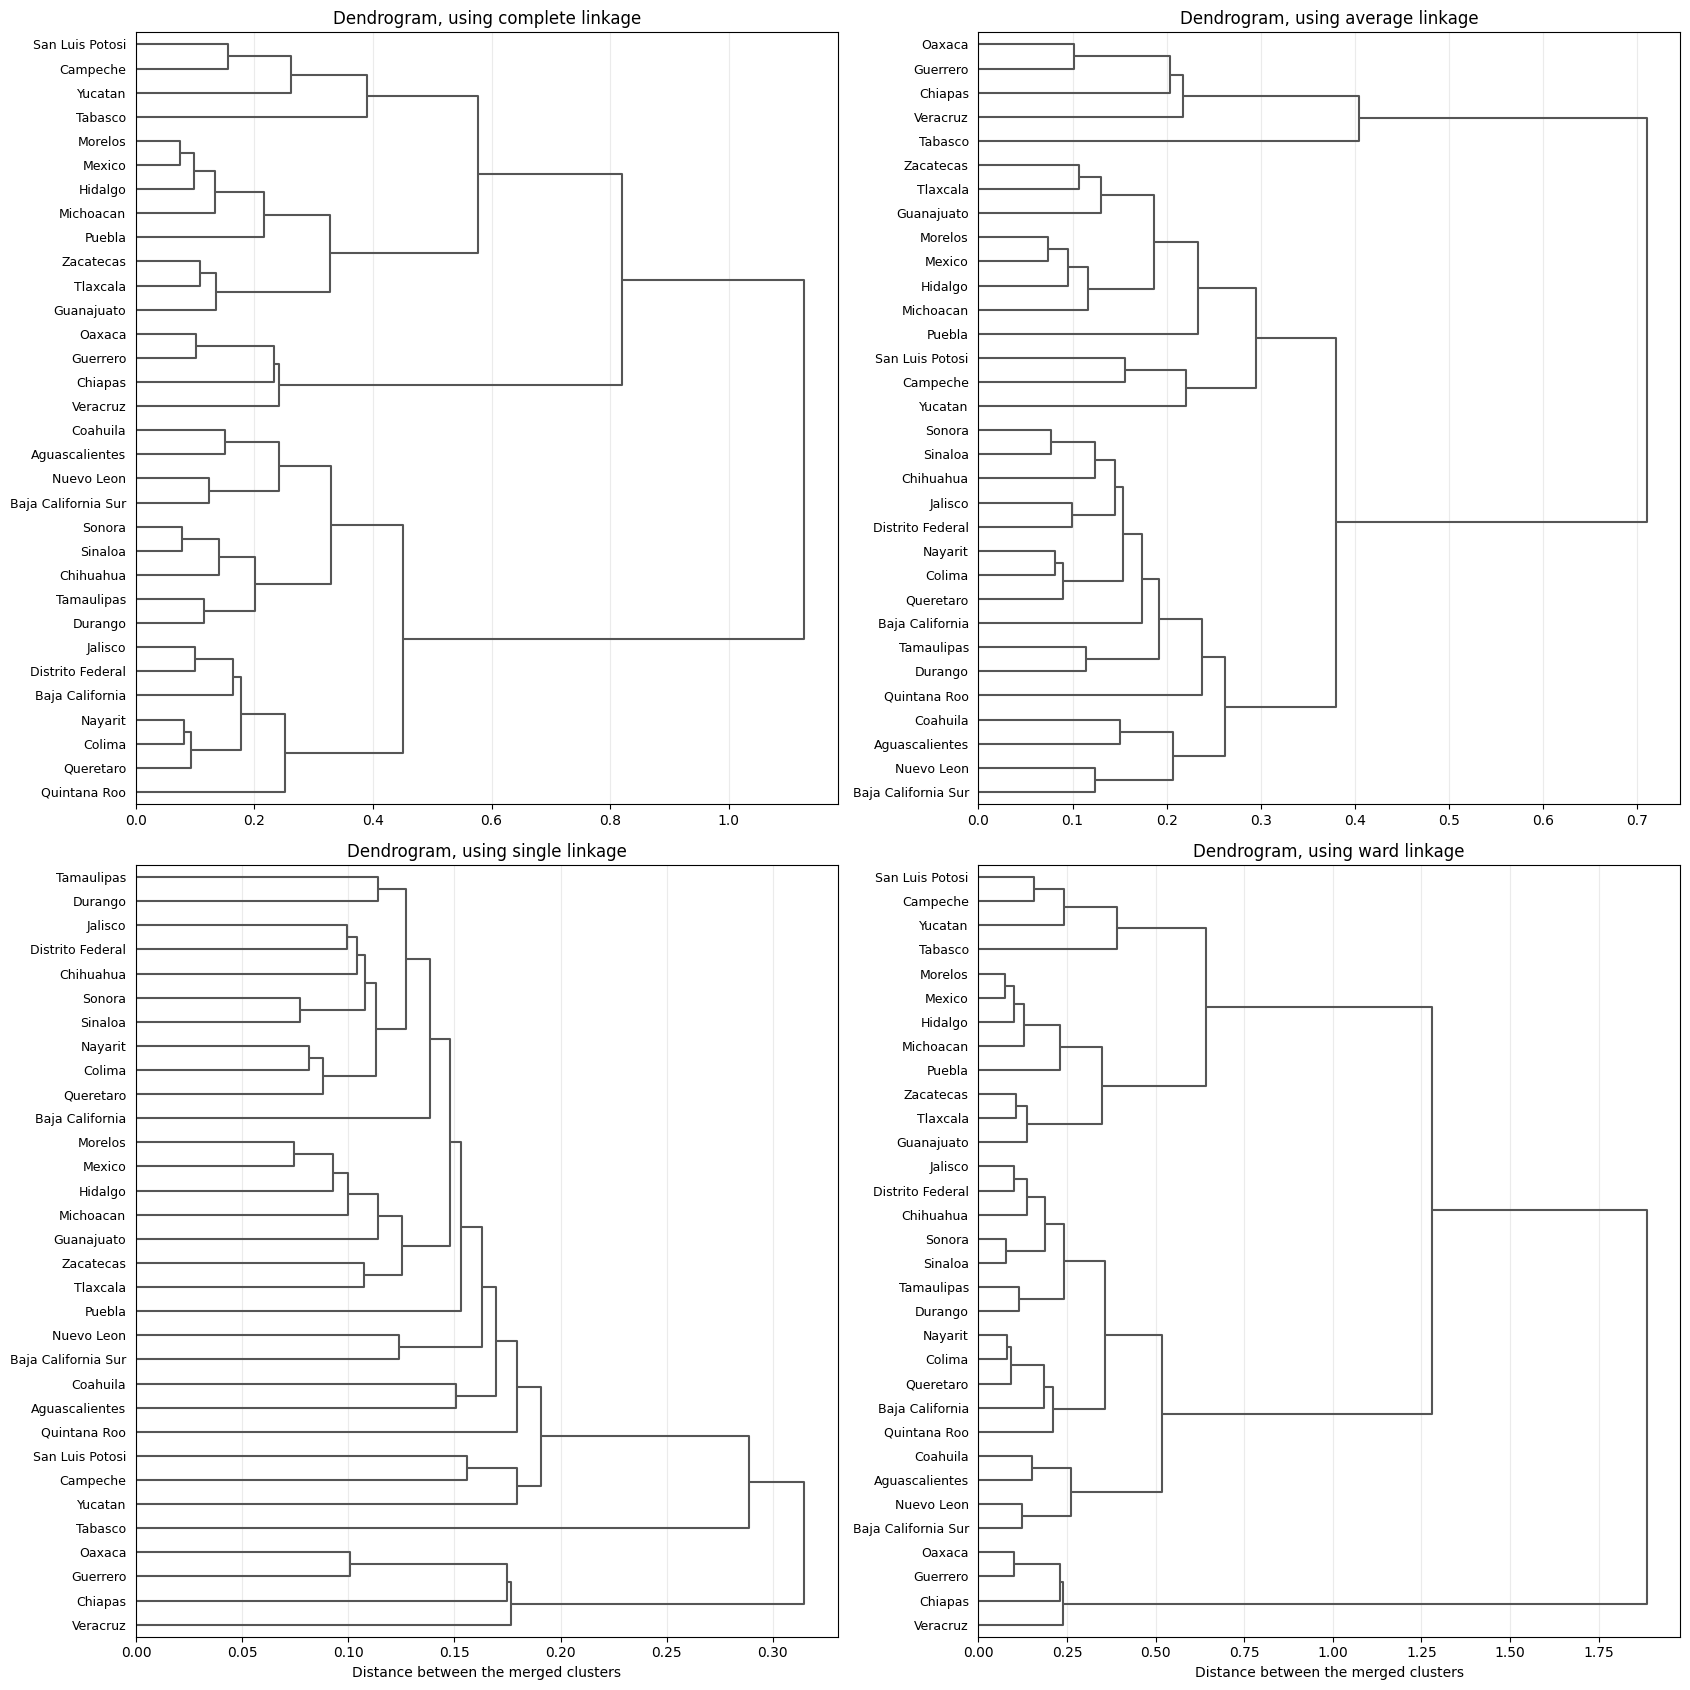

In [5]:
linkages = {method: shc.linkage(data, method=method) for method in ['complete', 'average', 'single', 'ward']}

fig, axes = plt.subplots(2, 2, figsize=(17, 17))
for ax, (method, Z) in zip(axes.ravel(), linkages.items()):
    plot_dendrogram(ax, Z, title=f'Dendrogram, using {method} linkage')
for ax in axes[0]:
    ax.set_xlabel('')
plt.tight_layout()

## Three groups of states

We cut the dendrogram of Ward linkage in three clusters.

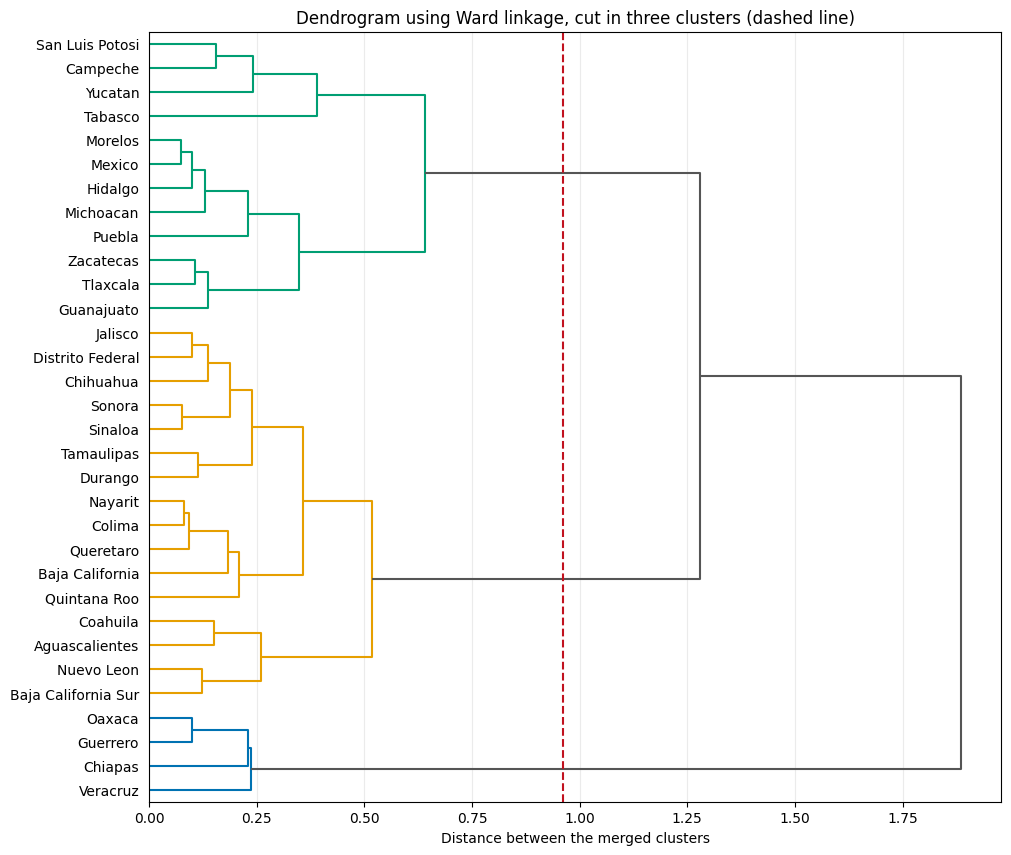

In [6]:
Z = linkages['ward']
n_clusters = 3

fig, ax = plt.subplots(figsize=(11, 10))
plot_dendrogram(ax, Z, n_clusters, 'Dendrogram using Ward linkage, cut in three clusters (dashed line)', font_size=10)

In [7]:
cluster_labels = ordered_clusters(Z, n_clusters)

for c in range(n_clusters):
    print(f'Cluster {c}:', ', '.join(np.array(state_names)[cluster_labels == c]))
    print()

Cluster 0: Chiapas, Guerrero, Oaxaca, Veracruz

Cluster 1: Aguascalientes, Baja California, Baja California Sur, Coahuila, Colima, Chihuahua, Distrito Federal, Durango, Jalisco, Nayarit, Nuevo Leon, Queretaro, Quintana Roo, Sinaloa, Sonora, Tamaulipas

Cluster 2: Campeche, Guanajuato, Hidalgo, Mexico, Michoacan, Morelos, Puebla, San Luis Potosi, Tabasco, Tlaxcala, Yucatan, Zacatecas



### The indicators of each state

The states in the order of the dendrogram (from bottom to top there), with all their indicators. The three clusters are three levels of deprivation: the four states with the highest proportions in almost every indicator, an intermediate group, and the group with the lowest ones.

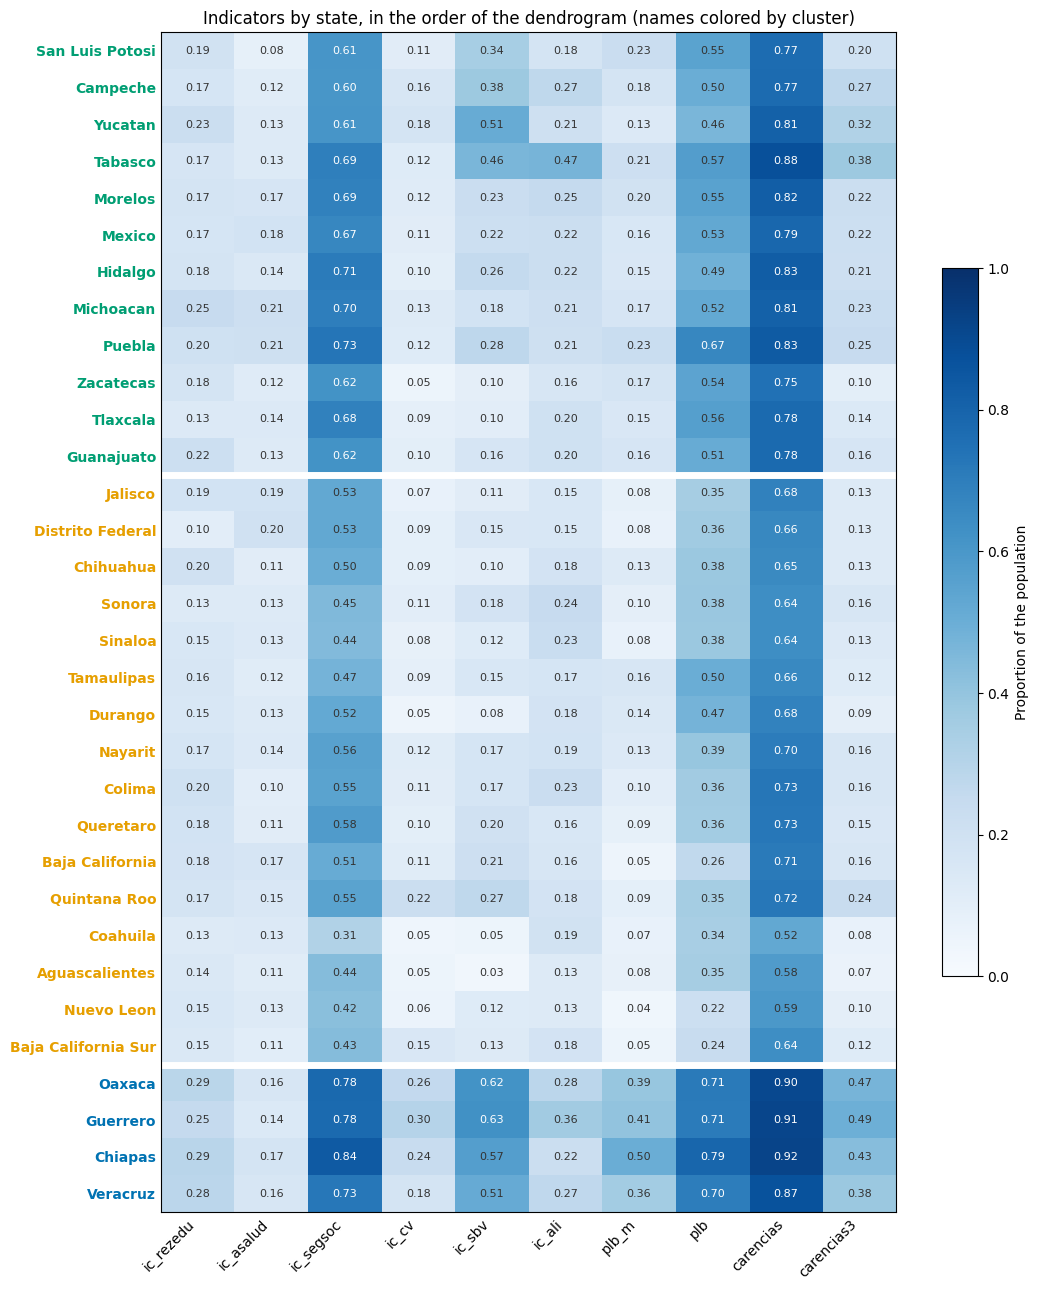

In [8]:
leaves = shc.leaves_list(Z)[::-1]
values = data.to_numpy()[leaves]

fig, ax = plt.subplots(figsize=(11, 13))
im = ax.imshow(values, cmap='Blues', vmin=0, vmax=1, aspect='auto')
for i in range(values.shape[0]):
    for j in range(values.shape[1]):
        ax.text(j, i, f'{values[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if values[i, j] > 0.6 else '#333333')
ax.set_xticks(range(data.shape[1]), data.columns, rotation=45, ha='right')
ax.set_yticks(range(len(leaves)), np.array(state_names)[leaves])
for tick, leaf in zip(ax.get_yticklabels(), leaves):
    tick.set_color(palette[cluster_labels[leaf]])
    tick.set_fontweight('bold')
# White lines between the clusters
changes = np.where(np.diff(cluster_labels[leaves]) != 0)[0]
for change in changes:
    ax.axhline(change+0.5, color='white', lw=5)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, label='Proportion of the population', shrink=0.6)
ax.set_title('Indicators by state, in the order of the dendrogram (names colored by cluster)')
plt.tight_layout()

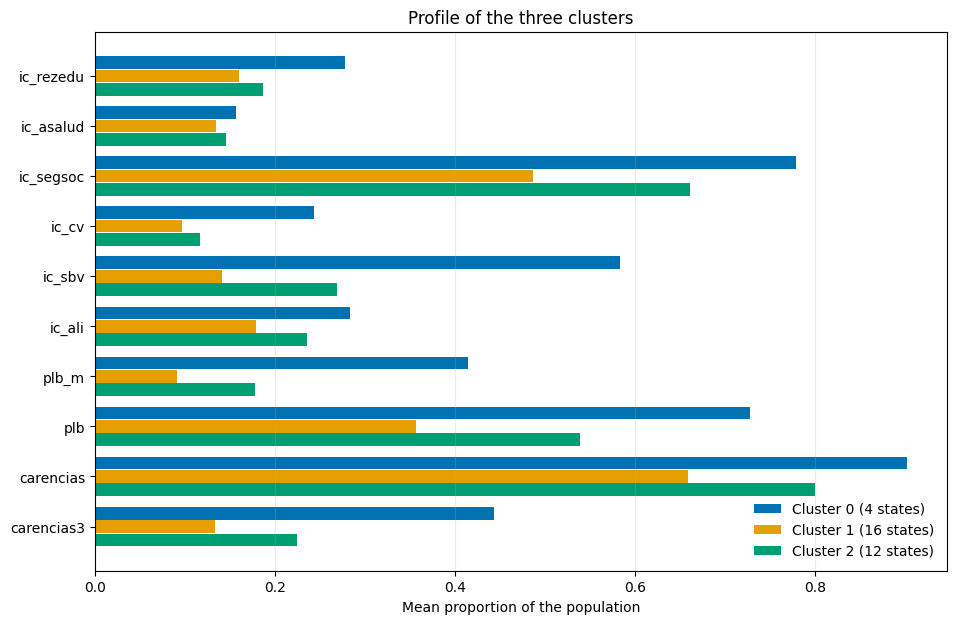

In [9]:
profiles = data.groupby(cluster_labels).mean()

fig, ax = plt.subplots(figsize=(11, 7))
pos = np.arange(data.shape[1])
width = 0.8/n_clusters
for c in range(n_clusters):
    ax.barh(pos + width*(c-(n_clusters-1)/2), profiles.loc[c], height=width*0.95, color=palette[c],
            label=f'Cluster {c} ({(cluster_labels == c).sum()} states)')
ax.set_yticks(pos, data.columns)
ax.invert_yaxis()
ax.set_xlabel('Mean proportion of the population')
ax.set_title('Profile of the three clusters')
ax.legend(loc='lower right', frameon=False)
ax.grid(True, axis='x', alpha=0.25)